In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

In [2]:
def detect_edges(image, filter_type="gaussian", edge_type="sobel", ksize=5, sigma=1):

    # Фильтрация
    if filter_type == "median":
        filtered = cv.medianBlur(image, ksize)
    elif filter_type == "gaussian":
        filtered = cv.GaussianBlur(image, (ksize, ksize), sigma)

    # Детекция границ
    if edge_type == "sobel":
        Gx = cv.Sobel(filtered, cv.CV_32F, 1, 0, ksize=3)
        Gy = cv.Sobel(filtered, cv.CV_32F, 0, 1, ksize=3)
        magnitude = cv.magnitude(Gx, Gy)
        return np.uint8(np.clip(magnitude, 0, 255))

    elif edge_type == "scharr":
        Gx = cv.Scharr(filtered, cv.CV_32F, 1, 0)
        Gy = cv.Scharr(filtered, cv.CV_32F, 0, 1)
        magnitude = cv.magnitude(Gx, Gy)
        return np.uint8(np.clip(magnitude, 0, 255))

    elif edge_type == "pruitt":
        Kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
        Ky = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)
        Gx = cv.filter2D(filtered, cv.CV_32F, Kx)
        Gy = cv.filter2D(filtered, cv.CV_32F, Ky)
        magnitude = cv.magnitude(Gx, Gy)
        return np.uint8(np.clip(magnitude, 0, 255))

    elif edge_type == "canny":
        return cv.Canny(filtered, 20, 70)

Тестируем разные фото

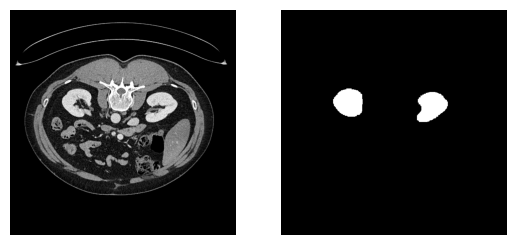

In [3]:
image = cv.imread("sample_data/img_000036.png")
image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
mask = cv.imread("sample_data/mask_000036.png")

fig, axs = plt.subplots(1, 2)
[ax.axis("off") for ax in axs.ravel()]
axs[0].imshow(image, "gray")
axs[1].imshow(mask, "gray")

plt.show()

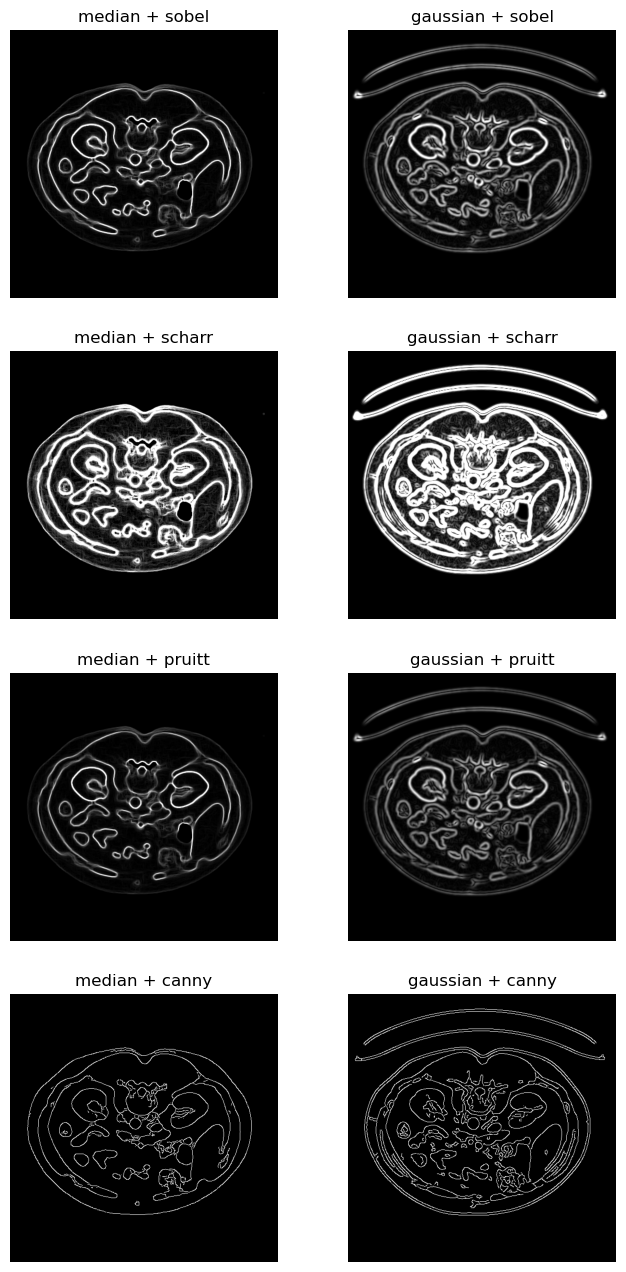

In [4]:
ksize = 13
sigma = 2

plt.rcParams['figure.figsize'] = [8, 16]
fig, axs = plt.subplots(4,2)
[ax.axis("off") for ax in axs.ravel()]

res = detect_edges(image, filter_type="median", edge_type="sobel", ksize=ksize)
axs[0, 0].imshow(res, 'gray')
axs[0, 0].set_title('median + sobel')

res = detect_edges(image, filter_type="median", edge_type="scharr", ksize=ksize)
axs[1, 0].imshow(res, 'gray')
axs[1, 0].set_title('median + scharr')

res = detect_edges(image, filter_type="median", edge_type="pruitt", ksize=ksize)
axs[2, 0].imshow(res, 'gray')
axs[2, 0].set_title('median + pruitt')

res = detect_edges(image, filter_type="median", edge_type="canny", ksize=ksize)
axs[3, 0].imshow(res, 'gray')
axs[3, 0].set_title('median + canny')

res = detect_edges(image, filter_type="gaussian", edge_type="sobel", ksize=ksize, sigma=sigma)
axs[0, 1].imshow(res, 'gray')
axs[0, 1].set_title('gaussian + sobel')

res = detect_edges(image, filter_type="gaussian", edge_type="scharr", ksize=ksize, sigma=sigma)
axs[1, 1].imshow(res, 'gray')
axs[1, 1].set_title('gaussian + scharr')

res = detect_edges(image, filter_type="gaussian", edge_type="pruitt", ksize=ksize, sigma=sigma)
axs[2, 1].imshow(res, 'gray')
axs[2, 1].set_title('gaussian + pruitt')

res = detect_edges(image, filter_type="gaussian", edge_type="canny", ksize=ksize, sigma=sigma)
axs[3, 1].imshow(res, 'gray')
axs[3, 1].set_title('gaussian + canny');

Лучшие:  
1: median + pruitt {ksize = 9}  
27: median + scharr {ksize = 11}  
32: median + sobel {ksize = 9}  
36: median + pruitt {ksize = 13}  